# v13: Wu, population betas only (no y in the gradient), Kev 800M

In [1]:
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

# The `beta_ols`, `beta_train` and `beta_population` packages live next to this notebook in `train-notebooks/beta-training/`
BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
if not (BETA_TRAINING_DIR / "beta_population").is_dir():
    raise RuntimeError(f"`beta_population` package not found in {BETA_TRAINING_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and the beta-training folder on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_population.config import PopulationTrainConfig
from beta_population.trainer import load_population_run, run_population_training
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import set_checkpointing, snapshot_trainable
from beta_train.trainer import load_run, run_training
from beta_train.validation import PopulationValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to train jaredpalmer/kev-0.8b in bf16")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0
# Recompute activations in backward (less VRAM, slower). Memory-only: not part of a run's identity
GRADIENT_CHECKPOINTING = False

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
set_checkpointing(kev_model, GRADIENT_CHECKPOINTING)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "gradient_checkpointing": GRADIENT_CHECKPOINTING,
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run and the step-0 validation start from them
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
gradient_checkpointing,False
model_load_sec,1.842


Snapshotted 376 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Wu is the training dataset (its inputs; its y only through the population betas below) and also a validator
# (in-sample: does beta-only training reduce Wu's population beta error?). Kriner and Grummon 2025 are held out.
ITEM_DATASETS = [         # training items are built for these
    "wu2025",
]
VALIDATION_DATASETS = [   # validation runs on these
    "wu2025",
    # "kriner2026",
    # "grummon2025",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Wu has one task variable, so its training piece is the whole dataset under its own name.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")

wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

TRAIN_DATASETS = ['wu2025']


# Training targets: the population betas (published-table stand-in)

In [5]:
# One target vector per training dataset and regression: the standardized human population betas (beta / sigma),
# in the spec's target order. This table is the only thing training sees of the respondents' choices.
target_std_betas_by_dataset = {}
for dataset_name in TRAIN_DATASETS:
    dataset_ols = human_ols_by_dataset[dataset_name]
    dataset_targets = {}
    for group, spec in regression_specs_by_dataset[dataset_name].items():
        group_ols = dataset_ols[dataset_ols["model"] == group].set_index("term")
        target_values = group_ols.loc[spec.target_labels, "std_beta"].to_numpy(dtype=np.float64)
        dataset_targets[group] = torch.tensor(target_values, dtype=torch.float64)
    target_std_betas_by_dataset[dataset_name] = dataset_targets

for dataset_name, dataset_targets in target_std_betas_by_dataset.items():
    for group, target in dataset_targets.items():
        labels = regression_specs_by_dataset[dataset_name][group].target_labels
        display(pd.Series(target.numpy(), index=labels, name=f"{dataset_name} | {group} target std beta").round(4).to_frame())

,wu2025 | wu2025 target std beta
Monthly bill: $110 vs $105,-0.1938
Monthly bill: $115 vs $105,-0.3559
Monthly bill: $120 vs $105,-0.5789
Monthly bill: $125 vs $105,-0.7664
Percentage of renewables: 30% vs 10%,0.1946
Percentage of renewables: 50% vs 10%,0.3413
Percentage of renewables: 100% vs 10%,0.4842
Locally produced renewables: Yes vs No,0.2085


# Validators and training items

In [9]:
# One fused validator per VALIDATION_DATASETS entry (population OLS from the dataset's module)
# Per-GPU-batch inference budgets: lower them if validation runs out of memory, raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000

validators = {}
for dataset_name in VALIDATION_DATASETS:
    validators[dataset_name] = PopulationValidator(
        beta_ols.DATASET_MODULES[dataset_name],
        choice_dfs[dataset_name],
        regression_specs_by_dataset[dataset_name],
        max_questions=VALIDATION_MAX_QUESTIONS,
        max_chars=VALIDATION_MAX_CHARS,
    )
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,graph_limits,prep_sec
validator,,,,,,,,
wu2025,fused,18591,1831,wu2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",2.788


In [10]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

,source
validator,
wu2025,computed


,wu2025
kl_loss,1.0700
beta_mse,0.0512
beta_mae,0.2093
beta_mape_pct,114.1426
spearman_rho,-0.2143
eval_prep_sec,0.2561
eval_gpu_sec,31.0294
eval_wall_sec,33.3584
eval_ms_per_task,1.7943


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Monthly bill: $110 vs $105,wu2025,-0.0969,-0.0068,0.0901,0.0901
Monthly bill: $115 vs $105,wu2025,-0.1779,-0.0121,0.1659,0.1659
Monthly bill: $120 vs $105,wu2025,-0.2894,-0.0171,0.2723,0.2723
Monthly bill: $125 vs $105,wu2025,-0.3832,-0.0247,0.3584,0.3584
Percentage of renewables: 30% vs 10%,wu2025,0.0973,-0.0075,-0.1048,0.1048
Percentage of renewables: 50% vs 10%,wu2025,0.1706,-0.0150,-0.1856,0.1856
Percentage of renewables: 100% vs 10%,wu2025,0.2421,-0.0399,-0.2820,0.2820
Locally produced renewables: Yes vs No,wu2025,0.1042,-0.1109,-0.2151,0.2151


In [11]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were
# already built for this data, tokenizer, and code
item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

items: wu2025:   0%|          | 0/18591 [00:00<?, ?it/s]

,items (rows),source
dataset,,
wu2025,18591,built


,items (rows),respondents,regression_groups
dataset,,,
wu2025,18591,1861,wu2025


# Find max micro chunk

In [12]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) Wu chunks
SEARCH_GRADIENT_CHECKPOINTING = GRADIENT_CHECKPOINTING   # search with the setting you train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

[W1117 16:26:24.242068808 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 25165824 bytes (free: 28704768, total: 33733804032).
[W1117 16:26:24.242249499 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 25165824 bytes (free: 28704768, total: 33733804032).
[W1117 16:26:33.110769613 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 73400320 bytes (free: 20316160, total: 33733804032).
[W1117 16:26:33.148181307 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 73400320 bytes (free: 62259200, total: 33733804032).


,chunk_size,dataset,rule,padded_tokens,fits,peak_gib,peak_pct_of_vram
0,1,wu2025,most padded tokens each,372,True,2.77,8.8
1,1,wu2025,longest state + longest branch + most questions,371,True,2.78,8.9
2,1,wu2025,longest branch + most questions,368,True,2.77,8.8
3,2,wu2025,longest state + longest branch + most questions,750,True,3.83,12.2
4,2,wu2025,most padded tokens each,744,True,3.82,12.2
5,2,wu2025,longest state + most questions,742,True,3.81,12.1
6,4,wu2025,longest state + longest branch + most questions,1500,True,5.87,18.7
7,4,wu2025,most padded tokens each,1488,True,5.84,18.6
8,4,wu2025,longest state + most questions,1484,True,5.83,18.6
9,8,wu2025,longest state + longest branch + most questions,3000,True,9.96,31.7


gradient_checkpointing=False | MAX_FITTING_MICRO_CHUNK = 27


# Train

In [13]:
MAX_FITTING_MICRO_CHUNK = 24
GRADIENT_CHECKPOINTING

False

In [26]:
# Run folders: one per run under RUNS_DIR (stats, betas per validation, checkpoints/best.pt, checkpoints/last.pt)
NOTEBOOK = "train-beta-v13-wu-beta-only-800m"
RUNS_DIR = BETA_TRAINING_DIR / "runs" / NOTEBOOK
# ONE validator's column picks checkpoints/best.pt. Both runs below use the same rule, Kriner's beta MSE, so the
# beta-only run and the KL-only control are picked the same way. Wu and Grummon 2025 are not used for selection.
BEST_METRIC = "wu2025/beta_mse"
BEST_MODE = "min"

from_scratch = True

# Settings shared by both runs (v8's S = 40 regime): sample size in tasks, sqrt-scaled peak LR, one epoch, OneCycle
SAMPLE_SIZE = 40
NUM_EPOCHS = 5
# Peak LR = BASE_LR_PER_TASK x sqrt(S) (v8's rule): S = 40 -> 4e-5
BASE_LR_PER_TASK = 5e-6 / math.sqrt(10)
PEAK_LR = scale_lr_for_sample_size(BASE_LR_PER_TASK, SAMPLE_SIZE)
# Rows (training items) seen between validations, per validator (all validators also run at step 0 and the last step).
# kriner2026 picks best.pt, so it runs often; wu2025 is the in-sample check; grummon2025 the held-out check
EVAL_EVERY_ROWS_BY_VALIDATOR = {
    "wu2025": 3200, 
    # "kriner2026": 1280, 
    # "grummon2025": 6400,
    }
EVAL_EVERY_BY_VALIDATOR = {}
for validator_name, eval_every_rows in EVAL_EVERY_ROWS_BY_VALIDATOR.items():
    EVAL_EVERY_BY_VALIDATOR[validator_name] = max(1, round(eval_every_rows / SAMPLE_SIZE))
MICRO_CHUNK = MAX_FITTING_MICRO_CHUNK
# Items per no-grad forward when the beta-only run fills its probability cache at step 0 (VRAM only; lower it on OOM)
CACHE_FILL_CHUNK = 32

# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": "fused",
    "eval_every_rows_by_validator": EVAL_EVERY_ROWS_BY_VALIDATOR,
    "base_lr_per_task": BASE_LR_PER_TASK,
}
runs = {}

,beta_only_config
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 40}
lr,0.00001
num_epochs,5
eval_every_by_validator,{'wu2025': 80}
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,24
cache_fill_chunk,32
gradient_checkpointing,False


from_scratch=True: deleting the existing run in /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v13-wu-beta-only-800m/beta_only_lr=1e-05_S=40_ep=5


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,lr,wu2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,
0,0,0,NaN,0.20474,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,NaN,33.35836,0.00000
80,1,3200,0.18608,0.15895,0.15895,1.77992,0.03974,0.14493,69.50718,0.97619,0.00000,33.32945,167.62688
160,1,6400,0.10380,0.17215,0.17215,3.69020,0.04304,0.19610,121.44899,0.97619,0.00001,33.24669,230.28266
240,1,9600,0.03704,0.15658,0.15658,5.53381,0.03914,0.17242,118.92705,0.97619,0.00001,33.27314,293.07555
320,1,12800,0.00905,0.14910,0.14910,7.02651,0.03727,0.14985,97.06012,0.92857,0.00001,32.87983,355.76289
400,1,15991,0.00288,1.21603,1.21603,8.51133,0.30401,0.47632,287.03591,-0.64286,0.00001,32.90595,418.19872
480,2,19191,0.00049,0.40652,0.40652,3.86617,0.10163,0.29150,192.71788,0.50000,0.00001,33.01851,480.81048
560,2,22382,0.00027,0.19318,0.19318,10.05247,0.04830,0.19683,100.82542,-0.50000,0.00001,32.98932,543.26828
640,2,25582,0.00391,0.19284,0.19284,12.78641,0.04821,0.19667,100.74295,-0.50000,0.00001,33.03304,605.88474


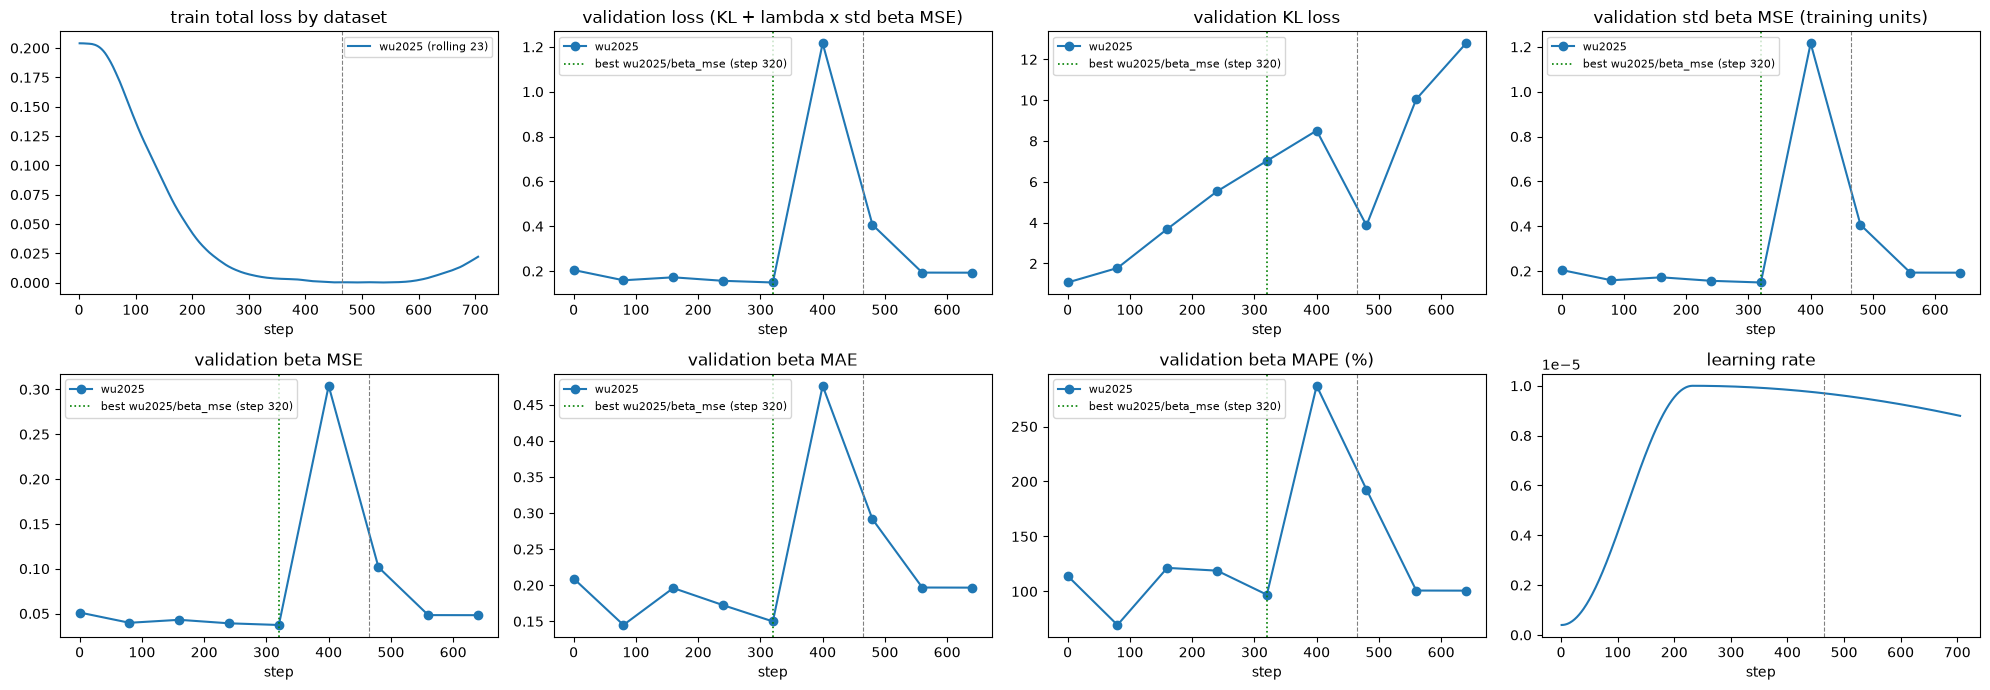

In [ ]:
# Beta-only run: the gradient is the population beta loss alone (Wu inputs, Wu population betas as targets, no y)
beta_only_config = PopulationTrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={dataset_name: SAMPLE_SIZE for dataset_name in TRAIN_DATASETS},
    lr=PEAK_LR,
    num_epochs=NUM_EPOCHS,
    eval_every_by_validator=EVAL_EVERY_BY_VALIDATOR,
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MICRO_CHUNK,
    cache_fill_chunk=CACHE_FILL_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
display(pd.Series(beta_only_config.as_dict(), name="beta_only_config").to_frame())
beta_only_run_dir = RUNS_DIR / f"beta_only_lr={PEAK_LR:g}_S={SAMPLE_SIZE}_ep={NUM_EPOCHS}"
runs["beta_only"] = run_population_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    target_std_betas_by_dataset=target_std_betas_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=beta_only_config,
    device=device,
    run_dir=beta_only_run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=from_scratch,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [ ]:
# KL-only control on the same Wu items and settings (existing trainer, beta_lambda = 0: uses y, no beta loss)
kl_only_config = TrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={dataset_name: SAMPLE_SIZE for dataset_name in TRAIN_DATASETS},
    beta_lambda=0.0,
    lr=PEAK_LR,
    num_epochs=NUM_EPOCHS,
    eval_every_by_validator=EVAL_EVERY_BY_VALIDATOR,
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
kl_only_run_dir = RUNS_DIR / f"kl_only_lr={PEAK_LR:g}_S={SAMPLE_SIZE}_ep={NUM_EPOCHS}"
runs["kl_only"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=kl_only_config,
    device=device,
    run_dir=kl_only_run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

# Beta-only vs KL-only

In [ ]:
# Load both runs from disk (works in a fresh kernel after the setup cells)
runs = {}
runs["beta_only"] = load_population_run(beta_only_run_dir)
runs["kl_only"] = load_run(kl_only_run_dir)

In [ ]:
# Per validator and run: step 0, the best step (picked by BEST_METRIC), and the last step: KL and beta MSE
comparison_rows = []
for run_label, run in runs.items():
    last_step = int(run.val_history_df.index[-1])
    for validator_name in VALIDATION_DATASETS:
        comparison_rows.append({
            "validator": validator_name,
            "run": run_label,
            "step0_kl": step0_validation[validator_name][0]["kl_loss"],
            "step0_beta_mse": step0_validation[validator_name][0]["beta_mse"],
            "best_step": run.best["step"],
            "kl_at_best": run.best_row[f"{validator_name}/kl_loss"],
            "beta_mse_at_best": run.best_row[f"{validator_name}/beta_mse"],
            "kl_at_last": run.val_history_df.loc[last_step, f"{validator_name}/kl_loss"],
            "beta_mse_at_last": run.val_history_df.loc[last_step, f"{validator_name}/beta_mse"],
        })
comparison_df = pd.DataFrame(comparison_rows)
for validator_name in VALIDATION_DATASETS:
    print(validator_name)
    validator_table = comparison_df[comparison_df["validator"] == validator_name].drop(columns="validator")
    display(validator_table.set_index("run").round(5))

In [ ]:
# Each validator's betas at the best step: human vs each run's model
for validator_name in VALIDATION_DATASETS:
    beta_columns = {}
    step0_beta_df = step0_validation[validator_name][1]
    beta_columns["human_pop_beta"] = step0_beta_df["human_pop_beta"]
    beta_columns["step0"] = step0_beta_df["model_pop_beta"]
    for run_label, run in runs.items():
        beta_columns[run_label] = run.best_validation[validator_name][1]["model_pop_beta"]
    print(validator_name)
    display(pd.DataFrame(beta_columns).round(4))

In [ ]:
# Beta-only run, per step: the cached population loss (the training objective) and the monitor KL (not in the gradient)
beta_only_steps = runs["beta_only"].step_df
display(runs["beta_only"].per_dataset_df.round(5))
display_every_steps = max(1, len(beta_only_steps) // 20)
step_columns = ["step", "population_loss", "monitor_kl", "grad_norm", "lr"]
display(beta_only_steps[step_columns].iloc[::display_every_steps].round(5))